# H2 supporting study: the final representation

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

from fsr.formats import FORMAT_NAMES
from fsr.h2_results import TRAINING_SEEDS, available
from fsr.models.registry import by_slug
from fsr.representation.plane import plane_view
from fsr.representation.separation import (
    SEPARATION_SUBDIR,
    full_space_separation,
    load_robustness,
    mitigation_frame,
    pair_frame,
    rank_frame,
    ratio_frame,
    within_model_ranks,
)
from fsr.representation.store import load_store

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "font.size": 9,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "grid.linewidth": 0.6,
        "grid.alpha": 0.45,
        "axes.edgecolor": "0.3",
        "axes.linewidth": 0.9,
    }
)

# the thesis text width in inches: A4 with 1 in margins. Figures are drawn at the
# width they are printed at, so their text prints at its true size.
TEXT_WIDTH = 6.27

BAR_FILL = sns.color_palette("pastel")[0]
BAR_EDGE = sns.color_palette("muted")[0]
MUTED_FILL = "0.88"
MUTED_EDGE = "0.6"
RULE = "0.35"
ERROR = "0.45"
# One colour per format, from seaborn's colour-blind palette.
FORMAT_COLOURS = dict(
    zip(
        FORMAT_NAMES,
        ["#0173b2", "#de8f05", "#029e73", "#cc78bc", "#d55e00"],
        strict=True,
    )
)

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
DATA_ROOT = ROOT / "data" / "nq"
FIG_DIR = ROOT / "notebooks" / "h2" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

SLUGS = available(DATA_ROOT)
SEEDS = list(TRAINING_SEEDS)
SHOWN_PASSAGES = 300
SPACES = {
    "raw": "full representation",
    "whitened": "format-specific directions",
}
HEIGHT = 0.36
CHANGE_LABEL = "change in separation, λ = 0 to chosen λ (%)"


def save(fig, name):
    """Write the figure as a vector PDF for the thesis and a PNG to read."""
    fig.tight_layout()
    for suffix in ("pdf", "png"):
        # No creation date, so a rerun rewrites an unchanged figure byte for byte.
        metadata = {"CreationDate": None} if suffix == "pdf" else None
        fig.savefig(
            FIG_DIR / f"{name}.{suffix}", bbox_inches="tight", metadata=metadata
        )


print(f"{len(SLUGS)} models, {len(SEEDS)} training seeds")

6 models, 5 training seeds


## Format directions

,separation,share_in_plane,full_space_separation
MiniLM-L6,0.873,0.177,0.498
MiniLM-L12,0.627,0.165,0.397
bge-base,0.006,0.179,0.065
bge-v2-m3,0.695,0.054,0.216
mxbai-v1,0.839,0.122,0.403
jina-v2,0.849,0.152,0.432


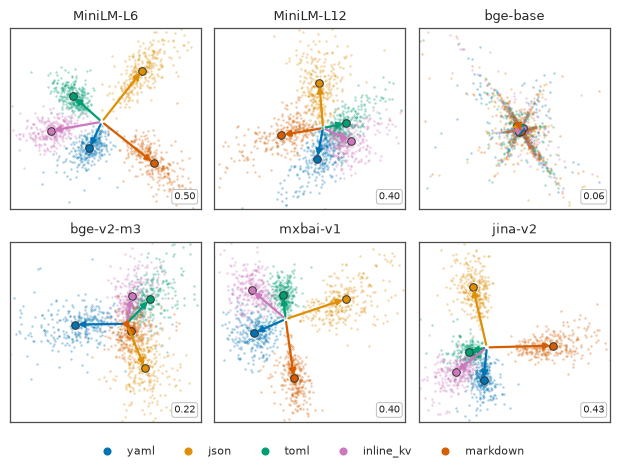

In [2]:
rng = np.random.default_rng(0)
views = {}
full_space = full_space_separation(DATA_ROOT, SLUGS)
fig, axs = plt.subplots(2, 3, figsize=(TEXT_WIDTH, 4.4))
for ax, slug in zip(axs.flat, SLUGS, strict=True):
    store = load_store(DATA_ROOT, "dev", slug)
    view = plane_view(store.features, whiten=True, gold_only=True)
    views[by_slug(slug).label] = view
    points = view["points"]
    shown = points[rng.choice(len(points), size=SHOWN_PASSAGES, replace=False)]
    for column, name in enumerate(FORMAT_NAMES):
        ax.scatter(
            shown[:, column, 0],
            shown[:, column, 1],
            s=3,
            color=FORMAT_COLOURS[name],
            alpha=0.35,
            lw=0,
        )
    for column, name in enumerate(FORMAT_NAMES):
        mean = view["means"][column]
        ax.annotate(
            "",
            xy=mean,
            xytext=(0, 0),
            arrowprops={"arrowstyle": "-|>", "color": FORMAT_COLOURS[name], "lw": 1.6},
        )
        ax.scatter(*mean, s=30, color=FORMAT_COLOURS[name], edgecolor="0.2", lw=0.7)
    low, high = np.percentile(shown.reshape(-1, 2), [1, 99], axis=0)
    pad = 0.08 * (high - low)
    ax.set_xlim(low[0] - pad[0], high[0] + pad[0])
    ax.set_ylim(low[1] - pad[1], high[1] + pad[1])
    ax.set_title(by_slug(slug).label, fontsize=9)
    ax.text(
        0.97,
        0.04,
        f"{full_space[by_slug(slug).label]:.2f}",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=7,
        bbox={"boxstyle": "round,pad=0.25", "fc": "white", "ec": "0.7", "lw": 0.6},
    )
    ax.set_xticks([])
    ax.set_yticks([])
fig.legend(
    handles=[
        Line2D([], [], marker="o", ls="", color=FORMAT_COLOURS[n], label=n)
        for n in FORMAT_NAMES
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.0),
    ncol=len(FORMAT_NAMES),
    frameon=False,
)
save(fig, "representation_directions")

pd.DataFrame(
    {
        "separation": {m: v["separation"] for m, v in views.items()},
        "share_in_plane": {m: v["passage_share"] for m, v in views.items()},
        "full_space_separation": full_space,
    }
).round(3)

Subtracting each passage's mean over its five renderings leaves only what the
formats change. After whitening, which rescales the representation so that the
directions in which passages also differ in content do not dominate, the formats
point in distinct directions. On gold passages not used to fit the plane, the
formats form separate clusters in every model but bge-base, which separates least
(0.01 in the plane, 0.06 in the full whitened space, given in each panel's box).
In the full space, MiniLM-L12 separates about as well as mxbai-v1 and jina-v2,
and bge-v2-m3 less. The plotted directions hold between 5% and 18% of each
passage's shift.

## Format pairs and score sensitivity

,raw_rho,raw_p,whitened_rho,whitened_p
MiniLM-L6,0.94,0.0,-0.07,0.85
MiniLM-L12,0.94,0.0,0.02,0.96
bge-base,0.87,0.0,-0.52,0.13
bge-v2-m3,0.93,0.0,0.58,0.08
mxbai-v1,0.96,0.0,-0.08,0.83
jina-v2,0.85,0.0,0.07,0.85
all models,0.90,0.0,0.39,0.00


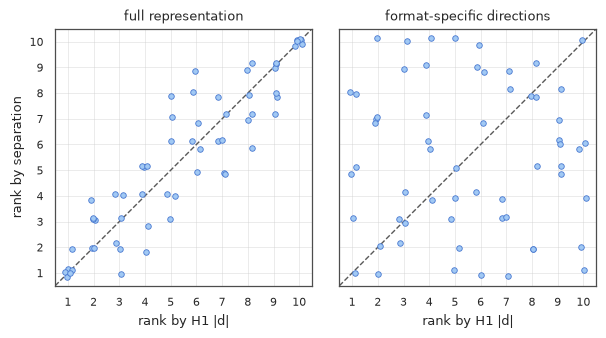

In [3]:
pairs = pair_frame(DATA_ROOT, SLUGS)
ranks = within_model_ranks(pairs)
# a small jitter so pairs with the same ranks do not hide each other
jitter = np.random.default_rng(0).uniform(-0.18, 0.18, size=(len(ranks), 2))

fig, axs = plt.subplots(1, 2, figsize=(TEXT_WIDTH, 3.2), sharex=True, sharey=True)
for ax, (space, title) in zip(axs, SPACES.items(), strict=True):
    ax.plot([0.5, 10.5], [0.5, 10.5], color=RULE, ls="--", lw=1, zorder=1)
    ax.scatter(
        ranks["h1_abs_d"] + jitter[:, 0],
        ranks[space] + jitter[:, 1],
        s=16,
        color=BAR_FILL,
        edgecolor=BAR_EDGE,
        lw=0.6,
        zorder=3,
    )
    ax.set_title(title, fontsize=9)
    ax.set_xlim(0.5, 10.5)
    ax.set_ylim(0.5, 10.5)
    ax.set_xticks(range(1, 11))
    ax.set_yticks(range(1, 11))
    ax.set_aspect("equal")
    ax.set_xlabel("rank by H1 |d|")
axs[0].set_ylabel("rank by separation")
save(fig, "representation_pairs")
rank_frame(pairs).round(2)

Within each model, the ten format pairs are ranked by H1's |d| and by how far
they separate the gold passages. In the full representation the two rankings
almost coincide (rank correlation 0.85 to 0.96 on every model), as expected when
the score is read linearly from it; this checks that the separation recovers H1
where it should. In the format-specific directions they do not (-0.52 to 0.58,
significant on no model): the format-specific directions are not where the
score sensitivity H1 measured lies.

## Under the invariance term

,score_mean,score_sd,separation_mean,separation_sd
model,,,,
MiniLM-L6,-0.192,0.050,29.906,4.299
MiniLM-L12,-0.067,0.022,11.316,5.994
bge-base,-0.217,0.049,20.555,8.048
bge-v2-m3,-0.268,0.022,4.671,4.074
mxbai-v1,-0.085,0.021,11.303,1.413
jina-v2,-0.177,0.028,0.410,3.702


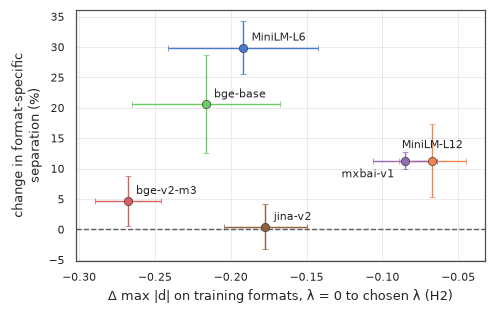

In [4]:
frame = mitigation_frame(DATA_ROOT, SLUGS, SEEDS)
summary = frame.groupby("model", sort=False).agg(
    score_mean=("score_delta", "mean"),
    score_sd=("score_delta", "std"),
    separation_mean=("separation_change", "mean"),
    separation_sd=("separation_change", "std"),
)
# labels placed by hand where two models' points sit close together
LABEL_OFFSETS = {"mxbai-v1": (-8, -12), "MiniLM-L12": (0, 9)}
colours = dict(
    zip(summary.index, sns.color_palette("muted", len(summary)), strict=True)
)

fig, ax = plt.subplots(figsize=(0.8 * TEXT_WIDTH, 3.2))
ax.axhline(0, color=RULE, ls="--", lw=1, zorder=1)
for model, row in summary.iterrows():
    ax.errorbar(
        row.score_mean,
        row.separation_mean,
        xerr=row.score_sd,
        yerr=row.separation_sd,
        fmt="o",
        ms=6,
        color=colours[model],
        mec="0.25",
        mew=0.5,
        ecolor=colours[model],
        elinewidth=1,
        capsize=2,
        zorder=3,
    )
    offset = LABEL_OFFSETS.get(model, (6, 5))
    ax.annotate(
        model,
        (row.score_mean, row.separation_mean),
        xytext=offset,
        textcoords="offset points",
        fontsize=8,
        ha="right" if offset[0] < 0 else "center" if offset[0] == 0 else "left",
    )
ax.set_xlabel("Δ max |d| on training formats, λ = 0 to chosen λ (H2)")
ax.set_ylabel("change in format-specific\nseparation (%)")
save(fig, "representation_mitigation")
summary.round(3)

In [5]:
pd.concat(
    {
        SPACES[space]: ratio_frame(DATA_ROOT, SLUGS, space, subdir=SEPARATION_SUBDIR)[
            ["training_mean", "held_out_mean"]
        ]
        for space in SPACES
    },
    axis=1,
).round(2)

full representation               format-specific directions  \
                 training_mean held_out_mean              training_mean   
MiniLM-L6                 1.19          1.33                       1.30   
MiniLM-L12                1.29          1.18                       1.11   
bge-base                  0.68          0.95                       1.21   
bge-v2-m3                 0.55          0.65                       1.05   
mxbai-v1                  1.17          1.19                       1.11   
jina-v2                   0.69          0.78                       1.00   

                          
           held_out_mean  
MiniLM-L6           1.33  
MiniLM-L12          1.11  
bge-base            1.31  
bge-v2-m3           1.07  
mxbai-v1            1.11  
jina-v2             1.05

Across models, how much the invariance term reduces maximum |d| on the training
formats bears no relation to how its format-specific separation changes. The
models reducing most, bge-v2-m3 and bge-base, change by 5% and 21%, and those
reducing least, MiniLM-L12 and mxbai-v1, by 11%. On average the separation rises
or holds level on every model, from 0% on jina-v2 to 30% on MiniLM-L6; two of
jina-v2's five seeds fall slightly below zero. In the full representation,
separation falls on bge-base, bge-v2-m3 and jina-v2 and rises on the other three.

## Robustness to the whitening

In [6]:
load_robustness(DATA_ROOT).round(3)

,bge_base_separation,other_lowest_separation,pooled_rho,lowest_ratio,highest_ratio
"shrinkage 0.0001, split 0",0.094,0.727,0.376,1.031,1.279
"shrinkage 0.001, split 0",0.053,0.636,0.386,1.004,1.326
"shrinkage 0.01, split 0",0.078,0.517,0.399,0.978,1.526
"shrinkage 0.001, split 1",0.055,0.629,0.360,0.994,1.382
"shrinkage 0.001, split 2",0.062,0.629,0.382,1.000,1.316


The whitened results hold across regularisation constants from 0.0001 to 0.01
and three record splits: bge-base remains the model that separates least, the
pooled correlation with H1's |d| stays between 0.36 and 0.40, and format-specific
separation under the invariance term stays within 2% of its value at λ = 0 or
above it on every model.